<a href="https://colab.research.google.com/github/owel569/Caf--restaurant/blob/main/05_Comparaison_Graphiques_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 – Comparaison des 4 pipelines (graphiques)

Ce notebook ne refait aucune inférence : il lit les fichiers `results/*.json` produits par les notebooks 01 à 04
et génère les graphiques demandés (débit, temps d'inférence, Top-1, énergie, barres d'erreur = écart-type).

**Avant de lancer :** place les 4 (ou plus) fichiers JSON dans `results/`
(soit en clonant ton dépôt dans la cellule ci-dessous, soit en les important à la main dans Colab).

In [1]:
# Option A : cloner le dépôt public (remplace l'URL) ; Option B : uploader les JSON dans results/
REPO_URL = ""     # ex. "https://github.com/owel569/tp1-deploiement-ia.git"
import os, subprocess
if REPO_URL and not os.path.isdir("results"):
    subprocess.run(["git", "clone", REPO_URL, "repo"], check=True)
    os.chdir("repo")
os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
print(os.listdir("results"))

['results_export (2).zip', 'results_export (1).zip', 'results_export (3).zip', 'results_export.zip']


In [2]:
import glob
import zipfile
import os

zip_files = glob.glob("results/*.zip")
print(f"Fichiers ZIP trouvés : {zip_files}")

for zip_path in zip_files:
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("results")
    print(f"Décompressé : {zip_path}")

# Vérification des fichiers JSON extraits
json_files = glob.glob("results/*.json")
print(f"Fichiers JSON prêts : {json_files}")

Fichiers ZIP trouvés : ['results/results_export (2).zip', 'results/results_export (1).zip', 'results/results_export (3).zip', 'results/results_export.zip']
Décompressé : results/results_export (2).zip
Décompressé : results/results_export (1).zip
Décompressé : results/results_export (3).zip
Décompressé : results/results_export.zip
Fichiers JSON prêts : ['results/cpu1_pytorch_onnx_openvino.json', 'results/cpu2_pytorch_torchcompile.json', 'results/cpu_pytorch_eager.json', 'results/gpu1_pytorch_onnx_tensorrt_fp16.json', 'results/gpu2_pytorch_torchscript.json', 'results/gpu1_pytorch_onnx_tensorrt_fp32.json', 'results/gpu2_pytorch_torchcompile.json', 'results/cpu2_pytorch_torchscript.json', 'results/gpu_pytorch_eager.json']


In [3]:
import glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

R = [json.load(open(f)) for f in sorted(glob.glob("results/*.json"))]
assert len(R) >= 4, "Il manque des résultats : exécute d'abord les notebooks 01 à 04"

def g(r, k, s):
    v = r["stats"][k]
    return np.nan if v is None else v[s]

df = pd.DataFrame([{
    "id": r["id"], "label": r["label"], "hw": r["hw"], "main": r["is_main"], "group": r["group"],
    "build_s": r["build_time_s"],
    "thr_mean": g(r, "throughput", "mean"), "thr_std": g(r, "throughput", "std"),
    "thr_min": g(r, "throughput", "min"), "thr_max": g(r, "throughput", "max"),
    "pass_mean": g(r, "pass_s", "mean") * 1000, "pass_std": g(r, "pass_s", "std") * 1000,
    "batch_mean": g(r, "batch_ms", "mean"), "batch_std": g(r, "batch_ms", "std"),
    "img_mean": g(r, "img_ms", "mean"),
    "epi_mean": g(r, "energy_per_img_j", "mean"), "epi_std": g(r, "energy_per_img_j", "std"),
    "pw_mean": g(r, "power_w", "mean"),
    "top1": r["accuracy"]["top1"], "agree": r["accuracy"]["agreement_with_ref"],
    "maxdiff": r["accuracy"]["max_abs_logit_diff_vs_ref"],
} for r in R])
df["cv_pct"] = 100 * df.thr_std / df.thr_mean          # coefficient de variation du débit
df = df.sort_values(["hw", "group", "id"]).reset_index(drop=True)
COL = {"cpu": "tab:blue", "gpu": "tab:green"}
HATCH = {True: "", False: "//"}          # hachuré = variante / baseline
df

,id,label,hw,main,group,build_s,thr_mean,thr_std,thr_min,thr_max,...,batch_mean,batch_std,img_mean,epi_mean,epi_std,pw_mean,top1,agree,maxdiff,cv_pct
0,cpu_pytorch_eager,CPU baseline : PyTorch eager,cpu,False,baseline,0.000000,11.958238,0.002173,11.955290,11.960584,...,836.239501,0.152113,83.624361,NaN,NaN,NaN,0.66,1.0,0.000000,0.018175
1,cpu1_pytorch_onnx_openvino,CPU 1 : PyTorch→ONNX→OpenVINO,cpu,True,cpu1,3.637201,17.371663,0.242900,17.094466,17.625667,...,575.737421,8.057020,57.574027,NaN,NaN,NaN,0.66,1.0,0.000022,1.398252
2,cpu2_pytorch_torchcompile,CPU 2 : PyTorch→torch.compile (Inductor),cpu,True,cpu2,34.805976,14.239246,0.233777,13.990614,14.567991,...,702.421909,11.489589,70.243526,NaN,NaN,NaN,0.66,1.0,0.000020,1.641778
3,cpu2_pytorch_torchscript,CPU 2 (variante) : PyTorch→TorchScript,cpu,False,cpu2,8.208945,14.343936,0.185907,14.173603,14.636120,...,697.239802,8.951852,69.725157,NaN,NaN,NaN,0.66,1.0,0.000033,1.296070
4,gpu_pytorch_eager,GPU baseline : PyTorch eager,gpu,False,baseline,0.000000,921.077402,2.739846,916.884543,923.826906,...,10.855044,0.032343,1.085693,0.075206,0.007645,69.279776,0.66,1.0,0.000031,0.297461
5,gpu1_pytorch_onnx_tensorrt_fp16,GPU 1 : PyTorch→ONNX→TensorRT (FP16),gpu,False,gpu1,25.453559,2963.641913,25.907663,2934.047546,2996.609319,...,3.372296,0.029438,0.337443,0.024030,0.005761,71.293358,0.66,1.0,0.064439,0.874183
6,gpu1_pytorch_onnx_tensorrt_fp32,GPU 1 : PyTorch→ONNX→TensorRT (FP32),gpu,True,gpu1,9.053309,1163.662484,4.971089,1158.160906,1171.441181,...,8.591125,0.036838,0.859368,0.057947,0.006023,67.434006,0.66,1.0,0.000020,0.427193
7,gpu2_pytorch_torchcompile,GPU 2 : PyTorch→torch.compile (Inductor),gpu,True,gpu2,19.350266,880.473590,6.591876,873.079200,887.944435,...,11.355854,0.084860,1.135803,0.077411,0.007432,68.155909,0.66,1.0,0.000013,0.748674
8,gpu2_pytorch_torchscript,GPU 2 (variante) : PyTorch→TorchScript,gpu,False,gpu2,1.465983,1053.933239,6.559732,1047.553200,1062.070003,...,9.486346,0.058585,0.948856,0.063782,0.007689,67.218718,0.66,1.0,0.000023,0.622405


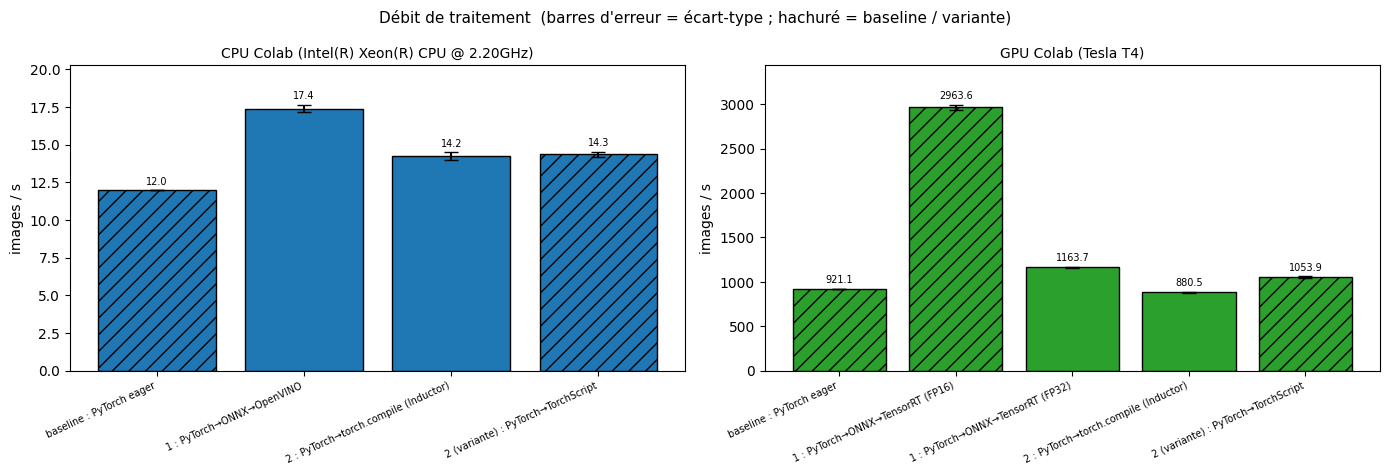

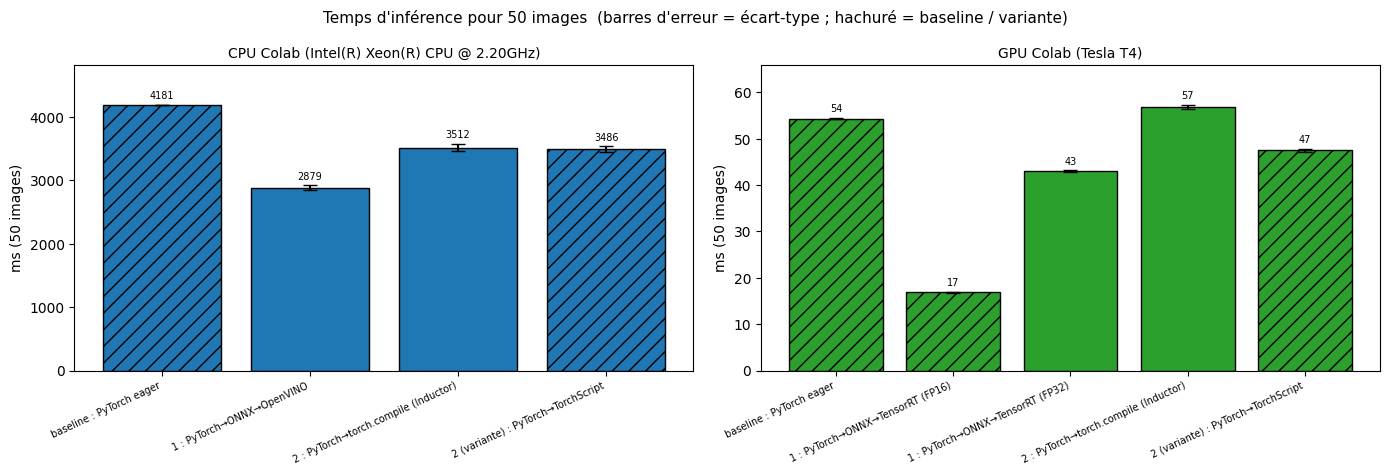

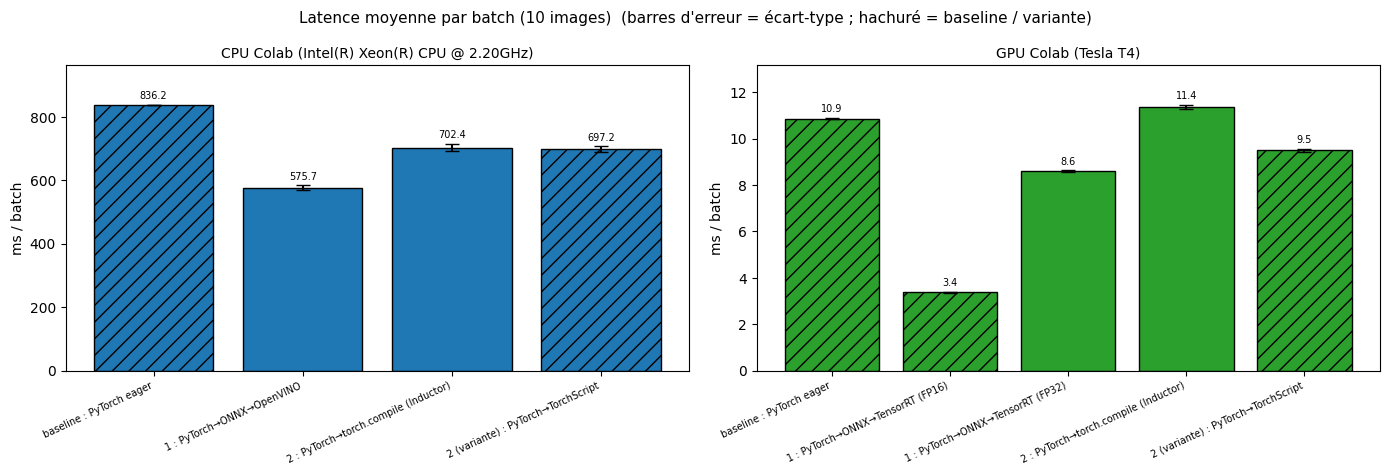

In [4]:
GPU_NAME = next((r["env"]["gpu"] for r in R if r["hw"] == "gpu"), "GPU")
CPU_NAME = next((r["env"]["cpu"] for r in R if r["hw"] == "cpu"), "CPU")
PANELS = [("cpu", f"CPU Colab ({CPU_NAME})"), ("gpu", f"GPU Colab ({GPU_NAME})")]

def bar(col, err, title, ylabel, fname, logy=False, fmt="{:.1f}"):
    """Un panneau par matériel (échelles indépendantes) : sinon les barres CPU (~10 img/s) sont invisibles à côté du GPU (~1000 img/s)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    for ax, (hw, name) in zip(axes, PANELS):
        d = df[(df.hw == hw) & df[col].notna()]
        ax.set_title(name, fontsize=10)
        if d.empty:
            ax.text(0.5, 0.5, "mesure indisponible\n(ex. compteur RAPL absent sur Colab CPU)", ha="center", va="center", transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([]); continue
        for i, (_, r) in enumerate(d.iterrows()):
            ax.bar(i, r[col], yerr=(r[err] if err else None), capsize=5, color=COL[r.hw], hatch=HATCH[bool(r.main)], edgecolor="k")
            top = r[col] + (r[err] if err and not np.isnan(r[err]) else 0)
            ax.annotate(fmt.format(r[col]), (i, top), ha="center", va="bottom", fontsize=7, xytext=(0, 3), textcoords="offset points")
        ax.set_xticks(range(len(d))); ax.set_xticklabels(d.label.str.replace(r"^(CPU|GPU) ", "", regex=True), rotation=25, ha="right", fontsize=7)
        ax.set_ylabel(ylabel); ax.margins(y=0.15)
        if logy: ax.set_yscale("log")
    fig.suptitle(title + "  (barres d'erreur = écart-type ; hachuré = baseline / variante)", fontsize=11)
    plt.tight_layout(); plt.savefig(f"figures/{fname}", dpi=150); plt.show()

bar("thr_mean", "thr_std", "Débit de traitement", "images / s", "01_debit.png")
bar("pass_mean", "pass_std", "Temps d'inférence pour 50 images", "ms (50 images)", "02_temps_50img.png", fmt="{:.0f}")
bar("batch_mean", "batch_std", "Latence moyenne par batch (10 images)", "ms / batch", "03_latence_batch.png")

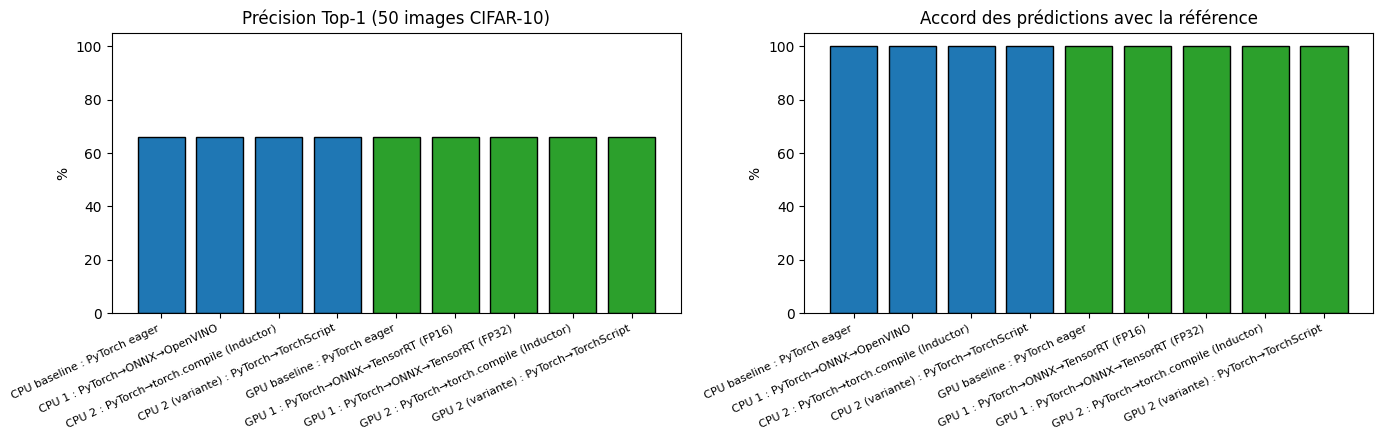

,label,top1,agree,maxdiff
0,CPU baseline : PyTorch eager,0.66,1.0,0.000000
1,CPU 1 : PyTorch→ONNX→OpenVINO,0.66,1.0,0.000022
2,CPU 2 : PyTorch→torch.compile (Inductor),0.66,1.0,0.000020
3,CPU 2 (variante) : PyTorch→TorchScript,0.66,1.0,0.000033
4,GPU baseline : PyTorch eager,0.66,1.0,0.000031
5,GPU 1 : PyTorch→ONNX→TensorRT (FP16),0.66,1.0,0.064439
6,GPU 1 : PyTorch→ONNX→TensorRT (FP32),0.66,1.0,0.000020
7,GPU 2 : PyTorch→torch.compile (Inductor),0.66,1.0,0.000013
8,GPU 2 (variante) : PyTorch→TorchScript,0.66,1.0,0.000023


In [5]:
# Top-1 et accord avec la référence PyTorch eager CPU FP32
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(range(len(df)), df.top1 * 100, color=[COL[h] for h in df.hw], edgecolor="k")
ax[0].set_title("Précision Top-1 (50 images CIFAR-10)"); ax[0].set_ylabel("%")
ax[1].bar(range(len(df)), df.agree * 100, color=[COL[h] for h in df.hw], edgecolor="k")
ax[1].set_title("Accord des prédictions avec la référence"); ax[1].set_ylabel("%")
for a in ax:
    a.set_xticks(range(len(df))); a.set_xticklabels(df.label, rotation=25, ha="right", fontsize=8); a.set_ylim(0, 105)
plt.tight_layout(); plt.savefig("figures/04_precision.png", dpi=150); plt.show()
df[["label", "top1", "agree", "maxdiff"]]

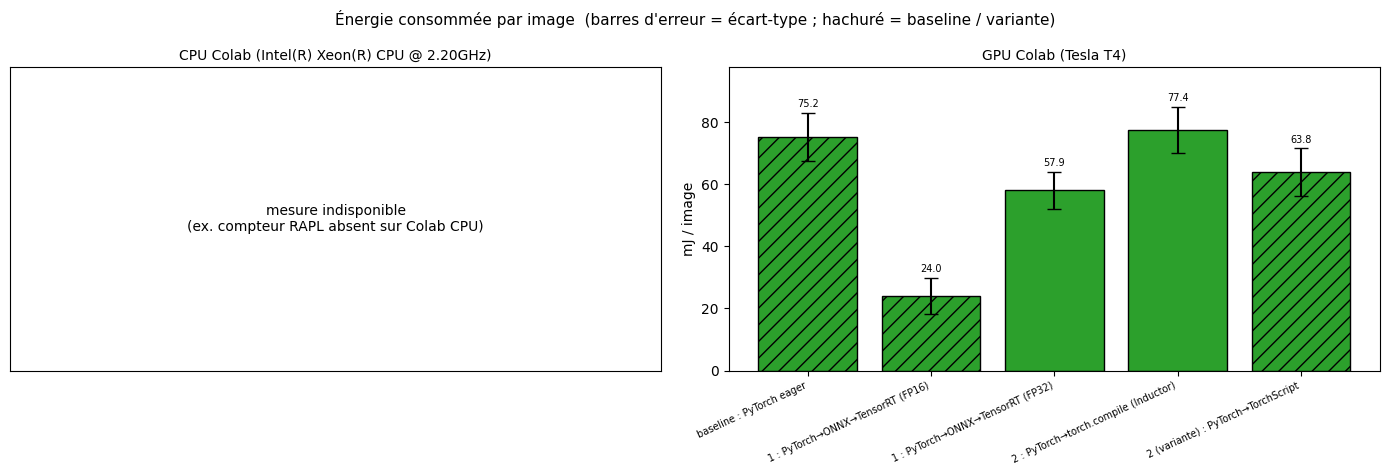

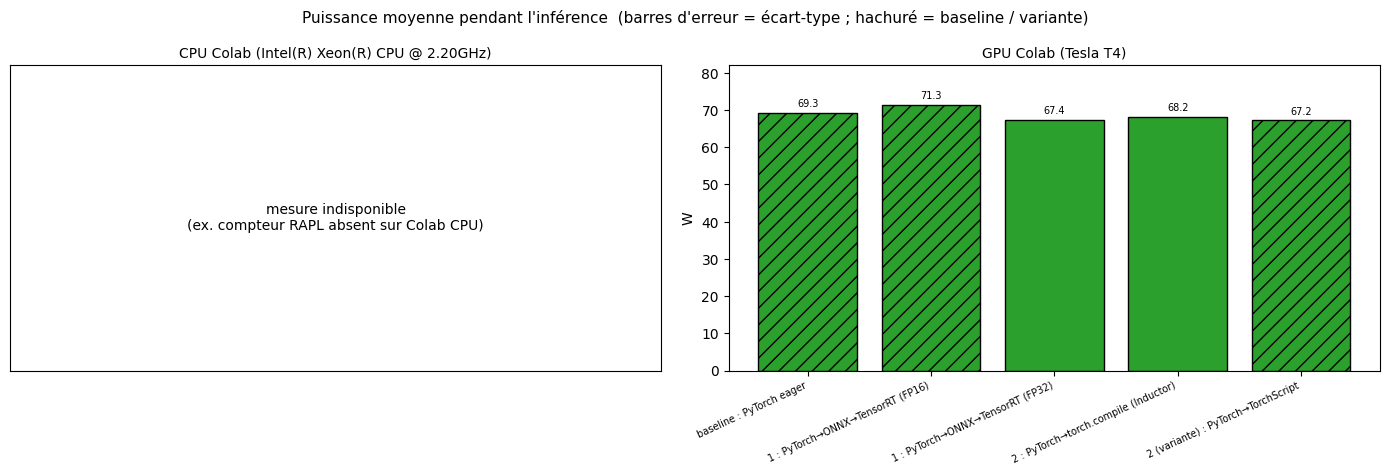

,label,epi_mean,pw_mean
0,CPU baseline : PyTorch eager,NaN,NaN
1,CPU 1 : PyTorch→ONNX→OpenVINO,NaN,NaN
2,CPU 2 : PyTorch→torch.compile (Inductor),NaN,NaN
3,CPU 2 (variante) : PyTorch→TorchScript,NaN,NaN
4,GPU baseline : PyTorch eager,0.075206,69.279776
5,GPU 1 : PyTorch→ONNX→TensorRT (FP16),0.024030,71.293358
6,GPU 1 : PyTorch→ONNX→TensorRT (FP32),0.057947,67.434006
7,GPU 2 : PyTorch→torch.compile (Inductor),0.077411,68.155909
8,GPU 2 (variante) : PyTorch→TorchScript,0.063782,67.218718


In [6]:
# Énergie par image (uniquement si les mesures existent : NVML pour le GPU, RAPL pour le CPU)
df["epi_mj"] = df.epi_mean * 1000; df["epi_mj_std"] = df.epi_std * 1000
bar("epi_mj", "epi_mj_std", "Énergie consommée par image", "mJ / image", "05_energie_par_image.png")
bar("pw_mean", None, "Puissance moyenne pendant l'inférence", "W", "06_puissance.png")
df[["label", "epi_mean", "pw_mean"]]

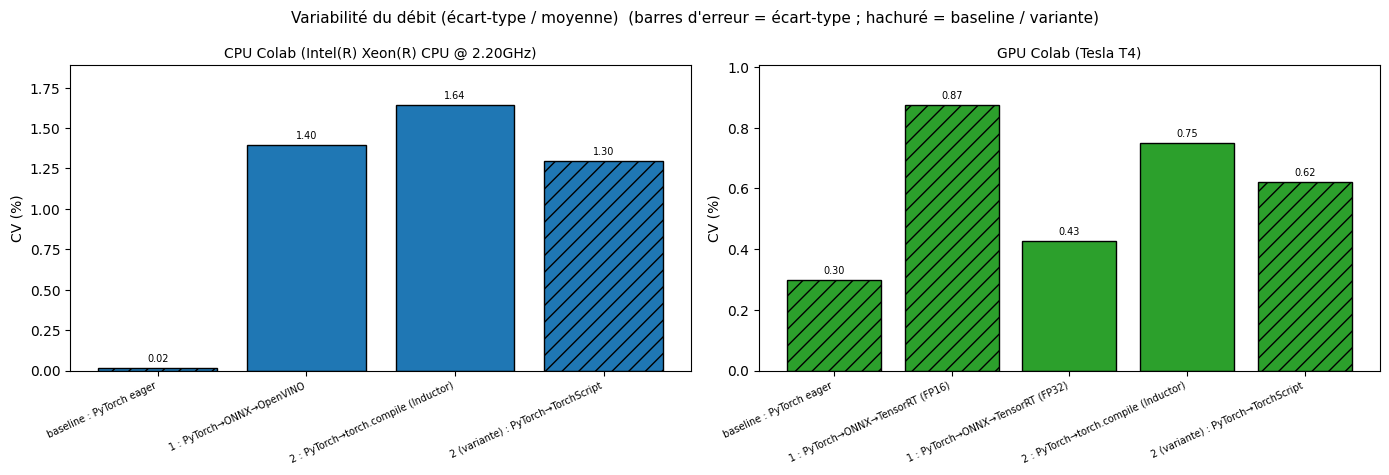

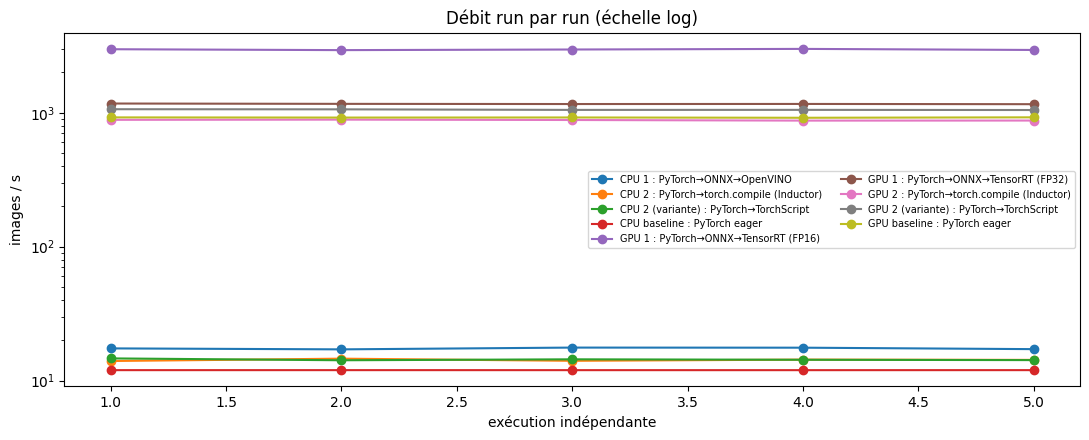

In [7]:
# Variabilité : coefficient de variation du débit + dispersion run par run
bar("cv_pct", None, "Variabilité du débit (écart-type / moyenne)", "CV (%)", "07_variabilite_cv.png", fmt="{:.2f}")

fig, ax = plt.subplots(figsize=(11, 4.5))
for r in R:
    ax.plot(range(1, len(r["runs"]) + 1), [x["throughput"] for x in r["runs"]], "o-", label=r["label"])
ax.set_xlabel("exécution indépendante"); ax.set_ylabel("images / s"); ax.set_yscale("log")
ax.set_title("Débit run par run (échelle log)"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig("figures/08_runs.png", dpi=150); plt.show()

In [8]:
# Accélération par rapport à la baseline PyTorch eager du même matériel
base = {r["hw"]: g(r, "throughput", "mean") for r in R if r["group"] == "baseline"}
sp = df[df.group != "baseline"].copy()
sp["speedup"] = [r.thr_mean / base[r.hw] if r.hw in base else np.nan for _, r in sp.iterrows()]
print(sp[["label", "thr_mean", "speedup", "build_s"]].to_string(index=False))

# Coût de mise en place : combien d'images pour amortir ?
def breakeven(r):
    if r.hw not in base or np.isnan(r.build_s): return np.nan
    t_img_base, t_img = 1 / base[r.hw], 1 / r.thr_mean
    return r.build_s / (t_img_base - t_img) if t_img_base > t_img else np.inf
sp["images_pour_amortir"] = sp.apply(breakeven, axis=1)
sp[["label", "build_s", "images_pour_amortir"]]

                                   label    thr_mean  speedup   build_s
           CPU 1 : PyTorch→ONNX→OpenVINO   17.371663 1.452694  3.637201
CPU 2 : PyTorch→torch.compile (Inductor)   14.239246 1.190748 34.805976
  CPU 2 (variante) : PyTorch→TorchScript   14.343936 1.199502  8.208945
    GPU 1 : PyTorch→ONNX→TensorRT (FP16) 2963.641913 3.217582 25.453559
    GPU 1 : PyTorch→ONNX→TensorRT (FP32) 1163.662484 1.263371  9.053309
GPU 2 : PyTorch→torch.compile (Inductor)  880.473590 0.955917 19.350266
  GPU 2 (variante) : PyTorch→TorchScript 1053.933239 1.144240  1.465983


,label,build_s,images_pour_amortir
1,CPU 1 : PyTorch→ONNX→OpenVINO,3.637201,1.395738e+02
2,CPU 2 : PyTorch→torch.compile (Inductor),34.805976,2.598252e+03
3,CPU 2 (variante) : PyTorch→TorchScript,8.208945,5.902111e+02
5,GPU 1 : PyTorch→ONNX→TensorRT (FP16),25.453559,3.401689e+04
6,GPU 1 : PyTorch→ONNX→TensorRT (FP32),9.053309,4.000059e+04
7,GPU 2 : PyTorch→torch.compile (Inductor),19.350266,inf
8,GPU 2 (variante) : PyTorch→TorchScript,1.465983,1.071168e+04


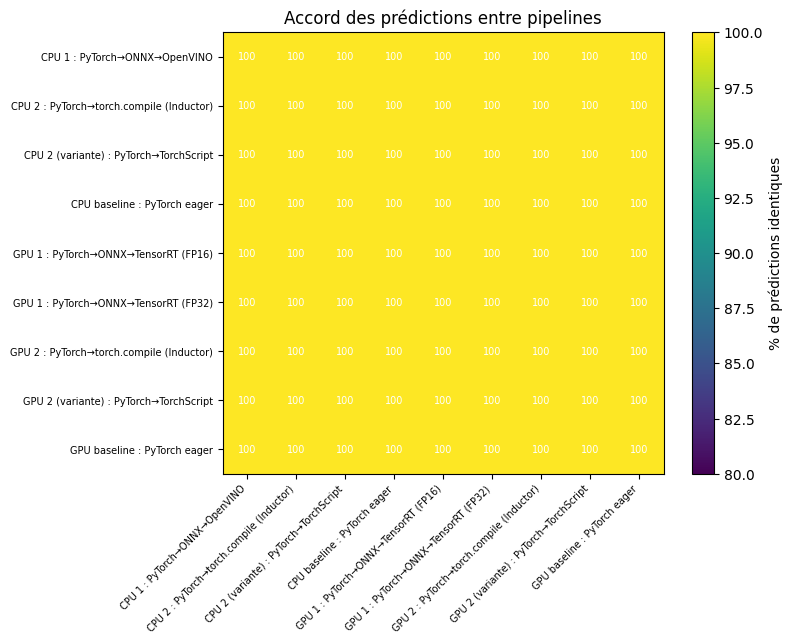

In [9]:
# Accord entre pipelines : matrice des prédictions identiques (50 images)
P = {r["label"]: np.array(r["predictions"]) for r in R}
names = list(P)
M = np.array([[ (P[a] == P[b]).mean() * 100 for b in names] for a in names])
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(M, vmin=min(80, M.min()), vmax=100, cmap="viridis")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right", fontsize=7)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=7)
for i in range(len(names)):
    for j in range(len(names)): ax.text(j, i, f"{M[i,j]:.0f}", ha="center", va="center", color="w", fontsize=7)
plt.colorbar(im, label="% de prédictions identiques"); ax.set_title("Accord des prédictions entre pipelines")
plt.tight_layout(); plt.savefig("figures/09_accord_pipelines.png", dpi=150); plt.show()

## Analyse (à rédiger pour le rapport – ne pas laisser les graphiques sans commentaire)
Pour chaque graphique, répondre aux questions suivantes **avec les chiffres obtenus** :

1. **Débit / temps d'inférence** : classement des pipelines ? Écart CPU ↔ GPU ? Quel est le gain d'OpenVINO et de TensorRT par rapport à PyTorch eager, et celui de `torch.compile` ? À quelles couches (fusion, kernels, précision) l'attribuer ?
2. **Précision** : les optimisations dégradent-elles Top-1 / les prédictions ? Le FP16 change-t-il des prédictions ? (n = 50 images : un écart d'une image = 2 points, à relativiser.)
3. **Énergie** : énergie/image CPU vs GPU, FP32 vs FP16 (préciser quelles mesures étaient disponibles : NVML pour le GPU, RAPL souvent indisponible sur Colab CPU).
4. **Variabilité** : CV du débit par pipeline, valeurs aberrantes, causes possibles (machine partagée, horloges GPU, thermal, compilation JIT).
5. **Compromis** : temps de mise en place (export, build TensorRT, compilation) vs gain à l'exécution ; quand quel pipeline est-il pertinent ?